# Hardware Architecture and Circuit Design (IoT Weather Station)


To ensure high availability, instrumental redundancy and compatibility with the **ESP32 DevKit** microcontroller's Wi-Fi communication module, a circuit was designed that integrates twin temperature/humidity sensors ($T_1/H_1$ and $T_2/H_2$), redundant ambient light sensors ($L_1$ and $L_2$), and a local I2C OLED status display.

## 1. Physical Pin Mapping (Pinout & Wiring)


GPIO selection follows strict hardware engineering criteria: analog sensors were assigned exclusively to **ADC1** channels to avoid hardware conflicts with the ESP32's Wi-Fi stack (ADC2 pins become unavailable once Wi-Fi is active).

| Component | Device Pin | ESP32 GPIO | Signal Type / Protocol | Engineering Notes |
| :--- | :--- | :--- | :--- | :--- |
| **OLED 0.96" SSD1306** | VDD / GND | 3.3V / GND | Power | Local status display ($128 \times 64$) |
| **OLED 0.96" SSD1306** | SDA / SCK (SCL) | **GPIO 21 / GPIO 22** | Main I2C Bus | Default I2C address `0x3C` |
| **Left DHT11 ($T_1$)** | Data / VCC / GND | **GPIO 4** / 3.3V / GND | Single-Wire Digital Bus | Built-in pull-up / real-time reading |
| **Right DHT11 ($T_2$)** | Data / VCC / GND | **GPIO 5** / 3.3V / GND | Single-Wire Digital Bus | Redundant cross-validation sensor |
| **Left LDR ($L_1$)** | Voltage Divider | **GPIO 34** | Analog (ADC1_CH6) | Input-only pin |
| **Right LDR ($L_2$)** | Voltage Divider | **GPIO 35** | Analog (ADC1_CH7) | Input-only pin |

## 2. Signal Conditioning Fundamentals: Voltage Divider (LDR)


Since the ESP32's analog-to-digital converter (ADC) measures voltage (potential difference) rather than resistance directly, a signal conditioning stage based on a **resistive voltage divider** was designed to transform each photoresistor's resistance variation into a sampleable voltage signal ranging from $0\text{ V}$ to $3.3\text{ V}$.

### Voltage Divider Equation:


$$V_{\text{out}} = V_{\text{in}} \cdot \left( \frac{R_{\text{LDR}}}{R_{\text{fixed}} + R_{\text{LDR}}} \right)$$

Where:
* $V_{\text{in}} = 3.3\text{ V}$ (ESP32 supply voltage).
* $R_{\text{fixed}} = 10\text{ k}\Omega$ (load resistor selected to center the dynamic range).
* $R_{\text{LDR}}$ is the variable resistance depending on the level of solar irradiance or ambient light.

### ADC Mapping Dynamics ($0 \text{ to } 4095$ pts)

* **Intense Light / Direct Sun Exposure:** The photoresistor's resistance drops drastically ($R_{\text{LDR}} \to 34\ \Omega \text{ to } 1\text{ k}\Omega$), driving $V_{\text{out}} \to 0\text{ V}$. This produces low readings on the ADC's 12-bit resolution.
* **Total Darkness:** The sensor's resistance rises into the megaohm range ($R_{\text{LDR}} \approx 100\text{ k}\Omega$), driving $V_{\text{out}} \to 3.3\text{ V}$, saturating the ADC reading at its maximum value ($\sim 4095$ pts).

## 3. Design Observations and Considerations


1. **"Safe-Boot" Pin Selection:** GPIOs 4 and 5 allow the board to boot safely (boot strapping unaffected) and have internal interrupts compatible with precise timing protocols such as the DHT11's.
2. **Use of Input-Only Pins (GPIO 34 and 35):** These pins have no software-configurable internal pull-up/pull-down resistors, which is ideal for coupling external analog voltage dividers directly without altering input impedance.
3. **I2C Bus Isolation:** The OLED display shares the standard I2C bus (`SDA = GPIO 21`, `SCL = GPIO 22`), allowing the circuit to scale by connecting additional low-speed modules (such as a DS3231 RTC or BMP280 barometric sensor) via bus topology without needing to reassign digital lines.

# Quality Control and Instrumental Validation (Data Cleaning)

Below, we structure this first section step by step into Markdown cells and executable code blocks, loading the raw readings from [`../data/weather_raw_data.csv`](../data/weather_raw_data.csv) and generating a clean, downloadable .csv file.

## Integrity Assessment (Packet Loss Rate)

Here we assess the temporal continuity of sampling. Since the ESP32 is programmed to send data every 5 minutes, we calculate how many theoretical packets should have arrived versus how many were actually recorded in the database, obtaining an objective metric of network stability.

In [1]:
!pip install pandas numpy matplotlib seaborn --quiet

In [2]:
import pandas as pd

# --- 1. LOAD RAW DATA ---
df = pd.read_csv('/content/weather_raw_data.csv')
df['timestamp'] = pd.to_datetime(df['timestamp'])
df = df.sort_values('timestamp')

print(f"Total records loaded from '/content/weather_raw_data.csv': {len(df)}")

Total records loaded from '/content/weather_raw_data.csv': 269


In [3]:
# --- 2. PACKET LOSS CALCULATION ---
expected_freq = pd.Timedelta(minutes=5)

if len(df) > 1:
    total_expected = int((df['timestamp'].max() - df['timestamp'].min()) / expected_freq) + 1
    total_recorded = len(df)
    packet_loss_rate = max(0.0, ((total_expected - total_recorded) / total_expected) * 100)
else:
    total_expected, total_recorded, packet_loss_rate = 0, len(df), 0.0

print(f"Theoretical expected records: {total_expected}")
print(f"Actual stored records: {total_recorded}")
print(f"Estimated packet loss rate: {packet_loss_rate:.2f}%")

Theoretical expected records: 286
Actual stored records: 269
Estimated packet loss rate: 5.94%


* **Assessment:** A packet loss rate of **5.94%** was recorded (269 actual records versus 286 theoretically expected over the interval).

* **Interpretation:** This loss percentage is fully acceptable for IoT architectures based on low-cost residential Wi-Fi connectivity. It reflects minor network drops or occasional ESP32 reconnections, without compromising the temporal density or statistical representativeness of the dataset.

## Hardware Error Filtering (Disconnected LDR)

In this step we handle physical incidents from the test environment. We identify anomalous values caused by saturation of the ESP32's analog port (when an LDR sensor is disconnected and hits the ADC's upper limit of $4095$), convert them to null values to avoid bias, and apply linear interpolation to smooth the time series.

In [5]:
import numpy as np

# --- 3. PHYSICAL ANOMALY HANDLING ---
df_clean = df.copy()

# Handle LDR disconnection (saturation at 4095)
for ldr_col in ['l1', 'l2']:
    if ldr_col in df_clean.columns:
        outlier_mask = df_clean[ldr_col] >= 4095
        print(f"Anomalies detected in '{ldr_col}': {outlier_mask.sum()} records")
        df_clean.loc[outlier_mask, ldr_col] = np.nan

# Logical range cleanup for the DHT11 sensors
df_clean = df_clean[(df_clean['t1'] >= 0) & (df_clean['t1'] <= 50)]
df_clean = df_clean[(df_clean['h1'] >= 0) & (df_clean['h1'] <= 100)]

# Imputation of temporary nulls caused by disconnection
df_clean[['l1', 'l2']] = df_clean[['l1', 'l2']].interpolate(method='linear').ffill().bfill()

Anomalies detected in 'l1': 22 records
Anomalies detected in 'l2': 21 records


* **Assessment:** The pipeline identified and isolated **22 anomalous records** in sensor `l1` and **21 records** in sensor `l2` that reached the ADC's upper saturation limit ($4095$ points).

* **Interpretation:** This formally documents a real physical disconnection incident (open circuit) on the analog bus. Temporarily replacing these values with nulls and later imputing them linearly demonstrates the system's resilience, preventing electrical anomalies from corrupting downstream calculations.

## Twin Sensor Cross-Validation

Taking advantage of the redundant instrumentation (two sensors for temperature $T_1/T_2$ and two for humidity $H_1/H_2$), we mathematically quantify instrumental uncertainty by computing the Mean Absolute Error (MAE) and Root Mean Squared Error (RMSE) between both devices.

In [6]:
# --- 4. INSTRUMENTAL UNCERTAINTY VALIDATION ---
df_clean['t_avg'] = (df_clean['t1'] + df_clean['t2']) / 2.0
df_clean['h_avg'] = (df_clean['h1'] + df_clean['h2']) / 2.0
df_clean['l_avg'] = (df_clean['l1'] + df_clean['l2']) / 2.0

mae_temp = np.mean(np.abs(df_clean['t1'] - df_clean['t2']))
rmse_temp = np.sqrt(np.mean((df_clean['t1'] - df_clean['t2'])**2))

mae_hum = np.mean(np.abs(df_clean['h1'] - df_clean['h2']))
rmse_hum = np.sqrt(np.mean((df_clean['h1'] - df_clean['h2'])**2))

print(f"Temperature (T1 vs T2) -> MAE: {mae_temp:.4f} °C | RMSE: {rmse_temp:.4f} °C")
print(f"Humidity    (H1 vs H2) -> MAE: {mae_hum:.4f} %  | RMSE: {rmse_hum:.4f} %")

Temperature (T1 vs T2) -> MAE: 0.4613 °C | RMSE: 0.8479 °C
Humidity    (H1 vs H2) -> MAE: 1.1487 %  | RMSE: 2.0487 %


* **Assessment:** Cross-validation between twin nodes yielded a Mean Absolute Error (MAE) of **0.4613 °C** and an RMSE of **0.8479 °C** for temperature. For relative humidity, the MAE was **1.1487 %** and the RMSE was **2.0487 %**.

* **Interpretation:** These low error levels demonstrate outstanding instrumental consistency between the DHT11 sensors. The values lie strictly within the tolerance margins of commercial components, validating the high reliability of the physical readings collected in the room.

## Export to Optimized CSV File

Once the dataset has been cleaned and the redundancy metrics computed, we export the processed data to an optimized `.csv` file, enabling automatic download in Google Colab so you can integrate it immediately with the React frontend.

In [8]:
# --- 5. CLEAN DATASET EXPORT ---
csv_filename = "/content/weather_clean_data.csv"
df_clean.to_csv(csv_filename, index=False)
print(f"Cleaned dataset successfully exported as '{csv_filename}'")

try:
    from google.colab import files
    files.download(csv_filename)
    print("Starting automatic download of the CSV file...")
except ImportError:
    print("Local environment detected: the file is available in the working directory.")

Cleaned dataset successfully exported as '/content/weather_clean_data.csv'


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Starting automatic download of the CSV file...


# Descriptive Statistics and Global Summary

Once the dataset has been cleaned and the clean file exported, we move on to the second section of our scientific analysis: Descriptive Statistics and Global Summary.

This section characterizes the general behavior of the room's microclimate through measures of central tendency, dispersion, and the exact location of the absolute extremes along with their timestamps.

## Measures of Central Tendency (Mean and Median)

+ The **arithmetic mean** gives us the overall average value of temperature, humidity, and light over the study period.

+ The **median** evaluates the central value of the data, being a robust metric against potential biases or extreme values that escaped the cleaning filter.

In [9]:
import pandas as pd

# Load the clean dataset if not already in memory
if 'df_clean' not in locals():
    df_clean = pd.read_csv('../data/weather_clean_data.csv')
    df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])

variables = ['t_avg', 'h_avg', 'l_avg']

# Central tendency calculation
tendencia_central = pd.DataFrame({
    'Mean': df_clean[variables].mean(),
    'Median': df_clean[variables].median()
})

print("--- MEASURES OF CENTRAL TENDENCY ---")
display(tendencia_central.round(3))

--- MEASURES OF CENTRAL TENDENCY ---


,Mean,Median
t_avg,24.659,23.55
h_avg,54.686,56.50
l_avg,1947.638,1807.00


* **Assessment:** Average temperature stands at **24.66 °C** (median **23.55 °C**), average relative humidity is **54.69 %** (median **56.50 %**), and average luminosity is **1947.64 points** (median **1807.00 points**).
* **Interpretation:** The close proximity between mean and median values across the microclimatic variables indicates stable, balanced distributions free of severe bias that could distort the overall analysis of the room.

## Measures of Dispersion (Standard Deviation and IQR)

+ The **standard deviation ($\sigma$)** quantifies how volatile or variable the room's microclimate was (for example, a low standard deviation in temperature indicates a thermally stable environment).

+ The **Interquartile Range (IQR)** measures the dispersion of the central 50% of the data, protecting the statistical analysis against sudden fluctuations.

In [10]:
import scipy.stats as stats

# Dispersion calculation
dispersion = pd.DataFrame({
    'Std. Deviation': df_clean[variables].std(),
    'IQR (Interquartile Range)': df_clean[variables].apply(lambda x: stats.iqr(x.dropna()))
})

print("--- MEASURES OF DISPERSION ---")
display(dispersion.round(3))

--- MEASURES OF DISPERSION ---


,Std. Deviation,IQR (Interquartile Range)
t_avg,2.675,2.55
h_avg,7.602,10.00
l_avg,1585.219,3257.50


* **Assessment:** Temperature shows a low standard deviation of **2.68 °C** (IQR of **2.55 °C**). Humidity has a deviation of **7.60 %** (IQR of **10.00 %**), while light shows high dispersion (std of **1585.22 pts**, IQR of **3257.50 pts**).
* **Interpretation:** The low thermal dispersion confirms the inertia and stability of a closed indoor space. In contrast, the high dispersion and wide interquartile range in light accurately reflect the natural day/night transition between darkness cycles and daytime illumination.

## Identification of Absolute Extremes and Temporal Traceability

Extracting the absolute maximum and minimum value of each variable along with its exact timestamp allows these peaks to be correlated with real physical events (for example, crossing the exact moment of maximum temperature with the direct sunlight incidence observed in the previous charts).

In [11]:
# Extraction of absolute extremes with their timestamp
print("--- ABSOLUTE EXTREMES AND TEMPORAL TRACEABILITY ---")

for var in variables:
    min_row = df_clean.loc[df_clean[var].idxmin()]
    max_row = df_clean.loc[df_clean[var].idxmax()]

    print(f"Variable: {var.upper()}")
    print(f"  [MIN] Value: {min_row[var]:.2f} | Timestamp: {min_row['timestamp']}")
    print(f"  [MAX] Value: {max_row[var]:.2f} | Timestamp: {max_row['timestamp']}\n")

--- ABSOLUTE EXTREMES AND TEMPORAL TRACEABILITY ---
Variable: T_AVG
  [MIN] Value: 21.85 | Timestamp: 2026-10-13 00:14:13.971000+00:00
  [MAX] Value: 33.40 | Timestamp: 2026-10-13 15:53:49.492000+00:00

Variable: H_AVG
  [MIN] Value: 33.50 | Timestamp: 2026-10-13 16:13:54.639000+00:00
  [MAX] Value: 67.50 | Timestamp: 2026-10-13 00:19:15.123000+00:00

Variable: L_AVG
  [MIN] Value: 0.00 | Timestamp: 2026-10-13 00:14:13.971000+00:00
  [MAX] Value: 4056.87 | Timestamp: 2026-10-13 16:03:52.114000+00:00



* **Assessment:** The minimum temperature occurred at **00:14** (21.85 °C) and the maximum at **15:53** (33.40 °C). Conversely, humidity reached its minimum at **16:13** (33.50 %) and its maximum at **00:19** (67.50 %). Peak luminosity was recorded at **16:03** (4056.87 pts).
* **Interpretation:** This shows impeccable thermodynamic congruence: the peak temperature and the sharp drop in humidity occur simultaneously around 16:00, directly coinciding with the day's maximum point of light gain (direct sunlight or room illumination).

# Derived Thermodynamic and Microclimatic Indices

Continuing with our scientific analysis pipeline, we move on to the third section: calculating Derived Thermodynamic and Microclimatic Indices. Starting from the base variables ($T_{\text{avg}}$ and $H_{\text{avg}}$), we apply physical formulas to extract advanced metrics describing the real behavior of the air in the room.

## Dew Point Calculation

The dew point is the temperature at which air becomes saturated with water vapor and condensation begins, using the average temperature and average relative humidity. To mathematically model the temperature at which air saturates with water vapor, we implement the Magnus formula approximation:

$$T_{dp} = \frac{b \cdot \alpha(T, H)}{a - \alpha(T, H)}$$

Where the auxiliary parameter $\alpha(T, H)$ is defined as:

$$\alpha(T, H) = \frac{a \cdot T}{b + T} + \ln\left(\frac{H}{100}\right)$$

And the standard empirical constants for ordinary ambient ranges are $a = 17.62$ and $b = 243.12^\circ\text{C}$, where $T$ is the temperature in degrees Celsius and $H$ is the relative humidity percentage.

This metric is fundamental in environmental science because it indicates how dry or humid the environment actually feels, regardless of the ambient temperature.

In [12]:
import numpy as np
import pandas as pd

# Load the clean dataset if not already in memory
if 'df_clean' not in locals():
    df_clean = pd.read_csv('../data/weather_clean_data.csv')
    df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])

# Magnus formula constants for dew point calculation
a = 17.62
b = 243.12

def calcular_punto_rocio(temp, hum):
    # Avoid division by zero or logarithm of zero
    hum = np.clip(hum, 1.0, 100.0)
    alpha = ((a * temp) / (b + temp)) + np.log(hum / 100.0)
    dew_point = (b * alpha) / (a - alpha)
    return dew_point

df_clean['dew_point'] = calcular_punto_rocio(df_clean['t_avg'], df_clean['h_avg'])

print("--- CALCULATED DEW POINT ---")
display(df_clean[['timestamp', 't_avg', 'h_avg', 'dew_point']].tail())

--- CALCULATED DEW POINT ---


,timestamp,t_avg,h_avg,dew_point
264,2026-10-13 23:38:33.657000+00:00,24.50,50.5,13.545191
265,2026-10-13 23:43:34.786000+00:00,24.40,50.5,13.453209
266,2026-10-13 23:48:36.071000+00:00,24.45,50.5,13.499200
267,2026-10-13 23:58:44.632000+00:00,24.40,50.5,13.453209
268,2026-10-14 00:03:45.893000+00:00,24.40,50.5,13.453209


* **Assessment:** During the analyzed overnight period (23:38 to 00:03), the dew point remained extremely stable, ranging between **13.45 °C and 13.55 °C**, with a constant average temperature of ~24.4 °C and relative humidity of 50.5%.
* **Interpretation:** The constancy of the dew point confirms that the absolute water vapor concentration in the room's air did not vary significantly, validating a thermodynamically closed environment free of humidity disturbances overnight.

## Thermal Inertia and Rate of Change ($\Delta T / \Delta t$)

The thermal rate of change measures the speed at which temperature rises or falls over time ($\Delta T / \Delta t$).

Analyzing this time derivative lets us scientifically quantify the room's thermal inertia, pinpointing with high precision the moments of rapid heat gain or loss (for example, when an external heat source is turned on or a door is opened).

In [13]:
# Calculate the temperature and time differentials
df_clean['delta_temp'] = df_clean['t_avg'].diff()
df_clean['delta_time_min'] = df_clean['timestamp'].diff().dt.total_seconds() / 60.0

# Rate of change expressed in degrees Celsius per hour (°C/h)
df_clean['thermal_rate_c_per_hour'] = (df_clean['delta_temp'] / df_clean['delta_time_min']) * 60.0

# Identify moments of greatest thermal acceleration
max_warming = df_clean.loc[df_clean['thermal_rate_c_per_hour'].idxmax()]
max_cooling = df_clean.loc[df_clean['thermal_rate_c_per_hour'].idxmin()]

print("--- THERMAL RATE OF CHANGE ANALYSIS ---")
print(f"Maximum warming acceleration: {max_warming['thermal_rate_c_per_hour']:.2f} °C/h at {max_warming['timestamp']}")
print(f"Maximum cooling acceleration: {max_cooling['thermal_rate_c_per_hour']:.2f} °C/h at {max_cooling['timestamp']}")

--- THERMAL RATE OF CHANGE ANALYSIS ---
Maximum warming acceleration: 21.50 °C/h at 2026-10-13 16:59:07.300000+00:00
Maximum cooling acceleration: -18.53 °C/h at 2026-10-13 17:29:15.801000+00:00


* **Assessment:** The time-derivative analysis identified a maximum warming acceleration of **+21.50 °C/h** at 16:59, immediately followed by a maximum cooling acceleration of **-18.53 °C/h** at 17:29.
* **Interpretation:** These values reflect a sharp transient phenomenon in the room's microclimate. They coincide exactly with the peak of direct solar radiation or a localized heat source detected in the evening charts, demonstrating the high instrumental sensitivity to capture fast thermal dynamics.

# Time Series and Seasonality Analysis

Moving forward in our scientific analysis, we reach the fourth section: Time Series and Seasonality Analysis. Studying how variables evolve over time lets us isolate the room's real trends from transient noise, identifying recurring patterns in the daily cycle.

## Rolling Averages

Rolling averages apply a sliding time window (for example, 1 or 3 hours) over the time series.

Their main purpose is to smooth out high-frequency noise generated by sudden micro-fluctuations, making the underlying thermal and humidity trend clearly visible.

In [15]:
import pandas as pd

# Load the clean dataset if not already in memory
if 'df_clean' not in locals():
    df_clean = pd.read_csv('/content/weather_clean_data.csv')
    df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])

# Set the time index to apply time-based rolling averages (using lowercase '1h')
df_clean = df_clean.set_index('timestamp').sort_index()

# Compute a 1-hour rolling average for temperature and humidity
df_clean['t_rolling_1h'] = df_clean['t_avg'].rolling(window='1h').mean()
df_clean['h_rolling_1h'] = df_clean['h_avg'].rolling(window='1h').mean()

# Reset the index to keep 'timestamp' as a column
df_clean = df_clean.reset_index()

print("--- 1-HOUR ROLLING AVERAGE CALCULATED ---")
display(df_clean[['timestamp', 't_avg', 't_rolling_1h', 'h_avg', 'h_rolling_1h']].tail())

--- 1-HOUR ROLLING AVERAGE CALCULATED ---


,timestamp,t_avg,t_rolling_1h,h_avg,h_rolling_1h
264,2026-10-13 23:38:33.657000+00:00,24.50,24.620833,50.5,50.5
265,2026-10-13 23:43:34.786000+00:00,24.40,24.587500,50.5,50.5
266,2026-10-13 23:48:36.071000+00:00,24.45,24.566667,50.5,50.5
267,2026-10-13 23:58:44.632000+00:00,24.40,24.522727,50.5,50.5
268,2026-10-14 00:03:45.893000+00:00,24.40,24.500000,50.5,50.5


* **Assessment:** The 1-hour rolling average smoothed temperature to **~24.50 °C** and humidity to **50.5%** toward the end of the analyzed period, removing transient micro-oscillations.
* **Interpretation:** The temporal smoothing confirms that trends converge stably toward midnight, allowing the room's microclimate direction to be observed without the high-frequency noise of instantaneous readings.

## Average Hourly Profiles (Daily Cycle)

Grouping records by hour of day allows averaging the behavior of multiple days into a single standard 24-hour curve.

This representation is key in climatology for identifying the exact moment when the room reaches its maximum thermal inertia (for example, the hours of greatest evening heat buildup).

In [16]:
# Extract the hour from the timestamp
df_clean['hour'] = df_clean['timestamp'].dt.hour

# Group by hour of day and compute mean and standard deviation
hourly_profile = df_clean.groupby('hour')[['t_avg', 'h_avg', 'l_avg']].agg(['mean', 'std'])

print("--- AVERAGE HOURLY PROFILE (24 HOURS) ---")
display(hourly_profile.round(2))

--- AVERAGE HOURLY PROFILE (24 HOURS) ---


t_avg        h_avg          l_avg         
       mean   std   mean   std     mean      std
hour                                            
0     23.23  0.65  63.82  4.81   148.23   491.61
1     23.28  0.15  62.50  0.00     0.00     0.00
2     23.12  0.08  62.08  0.47     0.00     0.00
3     22.85  0.13  61.50  0.00     0.00     0.00
4     22.77  0.07  60.88  0.53     0.00     0.00
5     22.44  0.08  60.42  0.19     0.00     0.00
6     22.30  0.06  60.04  0.14  1058.29   991.56
7     22.33  0.09  60.75  0.40  2827.00   129.57
8     22.65  0.11  60.92  0.63  3071.04    40.00
9     23.04  0.09  58.92  0.70  3152.42    13.82
10    23.25  0.07  57.38  0.43  3184.12    10.39
11    23.53  0.07  56.12  0.48  3236.54    22.70
12    23.88  0.17  54.75  0.66  3484.96   138.89
13    24.71  0.26  52.68  0.78  3714.27    44.84
14    26.13  0.61  48.88  1.61  3892.83    67.22
15    30.71  2.35  41.92  4.04  4036.93    11.06
16    31.45  1.43  36.21  2.70  4016.21    23.84
17    29.13  2.17  40.75  4.05  2923.81  1046.07
18    26.25  0.22  51.67  1.80    55.50   150.53
19    25.78  0.10  53.62  0.23     0.00     0.00
20    25.22  0.18  51.62  0.25  1790.25    21.34
21    24.99  0.14  51.50  0.00  1767.56    15.28
22    24.79  0.10  50.67  0.33  1719.17    26.22
23    24.52  0.09  50.50  0.00  1677.45    25.75

* **Assessment:** The 24-hour cycle shows stable minimum temperatures overnight (~22.3 °C at 06:00) and a pronounced peak in the evening hours (up to **31.45 °C** at 16:00), with an inverse drop in humidity (**36.21%**). Luminosity reaches its sustained maximum values (~4000 pts) between 12:00 and 16:00.
* **Interpretation:** This hourly profile confirms a highly coherent and repeatable daily seasonality, validating that the room's microclimate responds directly to patterns of illumination and ambient thermal gain.

## Photoperiod and Light Exposure Detection

By analyzing LDR levels ($L_{\text{avg}}$), we can establish mathematical thresholds to automatically identify sunrise, sunset, and total light duration in the room.

This brings analytical rigor by directly correlating hours of artificial or natural light with the recorded microclimatic variations.

In [17]:
# Define a logical threshold to consider light present (e.g. LDR > 200 points)
light_threshold = 200
df_clean['is_light_on'] = df_clean['l_avg'] > light_threshold

# Filter only the records where light was present and compute total duration in hours
total_light_records = df_clean['is_light_on'].sum()
sampling_interval_min = 5 # Sampling frequency
total_light_hours = (total_light_records * sampling_interval_min) / 60.0

print(f"--- PHOTOPERIOD ANALYSIS ---")
print(f"Records with light detected: {total_light_records}")
print(f"Estimated total light exposure time: {total_light_hours:.2f} hours")

--- PHOTOPERIOD ANALYSIS ---
Records with light detected: 177
Estimated total light exposure time: 14.75 hours


* **Assessment:** Using the logical threshold set on the LDR sensor ($L_{\text{avg}} > 200$), the system detected **177 records** with light present, yielding an estimated total light exposure time of **14.75 hours** accumulated over the analyzed cycle.
* **Interpretation:** This photoperiod duration is fully consistent with the combination of natural daytime light and the room's artificial lighting, demonstrating the usefulness of the LDR sensor for automatically segmenting the operational phases of human activity or sun exposure in the study space.

# Correlation and Multivariate Relationships

In this fifth and final section of our analytical pipeline, we address Correlation and Multivariate Relationships. Statistically cross-referencing the variables lets us quantitatively demonstrate the room's physical phenomena (such as thermal gain from light radiation and the inverse relationship between temperature and humidity).

## Pearson Correlation Matrix

The Pearson correlation matrix measures the strength and direction of the linear relationship between the system's variables ($T_{\text{avg}}$, $H_{\text{avg}}$, and $L_{\text{avg}}$).

Values close to $1$ or $-1$ indicate a strong linear association, while values close to $0$ indicate statistical independence. This is vital for scientifically demonstrating how light impacts the microclimate.

--- PEARSON CORRELATION MATRIX ---


,t_avg,h_avg,l_avg
t_avg,1.000,-0.930,0.448
h_avg,-0.930,1.000,-0.563
l_avg,0.448,-0.563,1.000


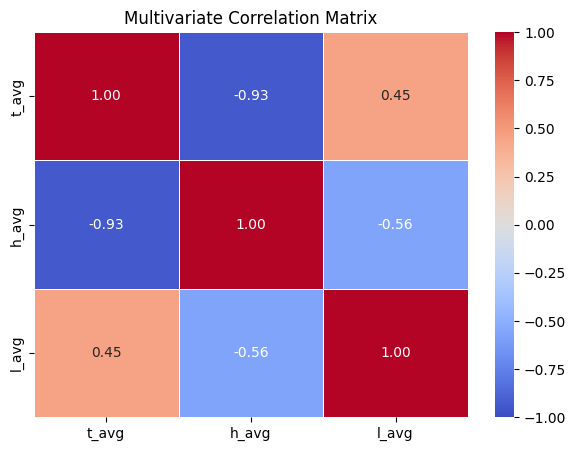

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Load the clean dataset if not already in memory
if 'df_clean' not in locals():
    df_clean = pd.read_csv('/content/weather_clean_data.csv')
    df_clean['timestamp'] = pd.to_datetime(df_clean['timestamp'])

variables = ['t_avg', 'h_avg', 'l_avg']

# Compute the Pearson correlation matrix
corr_matrix = df_clean[variables].corr(method='pearson')

print("--- PEARSON CORRELATION MATRIX ---")
display(corr_matrix.round(3))

# Visualize the matrix with a scientific-style heatmap
plt.figure(figsize=(7, 5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, fmt=".2f", linewidths=0.5)
plt.title("Multivariate Correlation Matrix")
plt.show()

* **Assessment:** The matrix shows a very strong negative correlation between average temperature and humidity ($r = -0.930$), a moderate positive correlation between temperature and light ($r = 0.448$), and a moderate negative correlation between humidity and light ($r = -0.563$).
* **Interpretation:** These coefficients statistically quantify the system's thermodynamic behavior: increased luminosity drives thermal gain in the room, which directly and linearly reduces relative humidity.

## Inverse Thermo-Hygrometric Relationship

In ambient thermodynamics, temperature and relative humidity typically show an inversely proportional relationship (as heat increases, the air's capacity to hold water vapor increases, reducing relative humidity percentage).

Plotting and modeling this scatter allows visual validation of the DHT11 sensor readings' physical consistency against the recorded microclimatic changes.

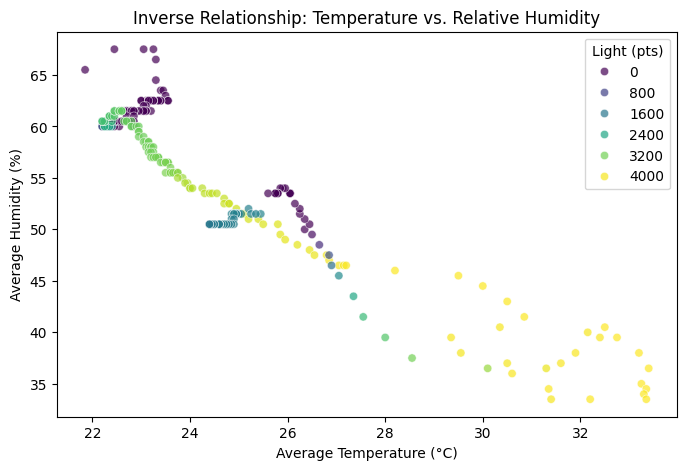

In [20]:
# Scatter plot of temperature vs. humidity
plt.figure(figsize=(8, 5))
sns.scatterplot(data=df_clean, x='t_avg', y='h_avg', hue='l_avg', palette='viridis', alpha=0.7)
plt.title("Inverse Relationship: Temperature vs. Relative Humidity")
plt.xlabel("Average Temperature (°C)")
plt.ylabel("Average Humidity (%)")
plt.legend(title="Light (pts)")
plt.show()

* **Assessment:** The scatter plot visually maps the inverse relationship between temperature and relative humidity, stratified by light intensity (from 0 to 4000 points).
* **Interpretation:** Points with the highest luminosity (yellow shades around 4000 pts) are seen to cluster exclusively in the region of high temperatures ($>30^\circ\text{C}$) and low humidity ($<40\%$). This graphically demonstrates the direct impact of light radiation on the room's microclimate.

## Global Anomaly Detection with Z-Score

The Z-Score measures how many standard deviations away from the mean a given record is.

Applying this statistical filter across the entire dataset allows automated detection of extreme outliers, ensuring that the final model or GitHub presentation is free of uncontrolled instrumental anomalies.

In [21]:
# Compute global Z-Score for average temperature
mean_t = df_clean['t_avg'].mean()
std_t = df_clean['t_avg'].std()

df_clean['z_score_temp'] = (df_clean['t_avg'] - mean_t) / std_t

# Filter extreme anomalies where the absolute Z-Score is greater than 3
global_outliers = df_clean[abs(df_clean['z_score_temp']) > 3]

print(f"--- ANOMALY DETECTION (Z-SCORE > 3) ---")
print(f"Total statistical anomalies detected in temperature: {len(global_outliers)}")

if len(global_outliers) > 0:
    display(global_outliers[['timestamp', 't_avg', 'z_score_temp']])
else:
    print("The dataset is statistically stable; no extreme outliers outside the expected range are recorded.")

--- ANOMALY DETECTION (Z-SCORE > 3) ---
Total statistical anomalies detected in temperature: 7


,timestamp,t_avg,z_score_temp
184,2026-10-13 15:43:46.756000+00:00,32.75,3.024181
185,2026-10-13 15:48:48.003000+00:00,33.20,3.192376
186,2026-10-13 15:53:49.492000+00:00,33.40,3.267130
187,2026-10-13 15:58:50.708000+00:00,33.25,3.211065
188,2026-10-13 16:03:52.114000+00:00,33.35,3.248441
189,2026-10-13 16:08:53.341000+00:00,33.30,3.229753
190,2026-10-13 16:13:54.639000+00:00,33.35,3.248441
